# Compression or Quantum Head

## Reproducible analysis for Article 09

This notebook reconstructs the audit summaries, performance tables, statistical comparisons, and every manuscript figure from immutable run artefacts. The experimental question is whether the dominant loss arises during the 384D-to-6D representation bottleneck or in the downstream classical/quantum decision head.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import SVG, display
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from article09.data import DatasetStore

FIG = ROOT / 'results' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='paper', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 130, 'savefig.dpi': 300, 'font.family': 'DejaVu Sans'})

def save_figure(fig, stem):
    fig.savefig(FIG / f'{stem}.svg', bbox_inches='tight')
    fig.savefig(FIG / f'{stem}.png', bbox_inches='tight')

## Environment and locked protocol

In [2]:
environment = json.loads((ROOT / 'environment' / 'hardware.json').read_text(encoding='utf-8'))
protocol = json.loads((ROOT / 'frozen' / 'protocol_v1.json').read_text(encoding='utf-8'))
pd.DataFrame({
    'Item': ['Python', 'PyTorch', 'CUDA', 'GPUs', 'Quantum backend', 'Final seeds'],
    'Value': [
        environment['python'].split()[0],
        environment['packages']['torch'],
        environment['torch_cuda'],
        ', '.join(environment['gpu_names']),
        protocol['selected_backend'],
        ', '.join(map(str, protocol['final_seeds']))
    ]
})

,Item,Value
0,Python,3.11.15
1,PyTorch,2.5.1+cu124
2,CUDA,12.4
3,GPUs,"NVIDIA GeForce RTX 3080 Ti, NVIDIA GeForce RTX..."
4,Quantum backend,default.qubit
5,Final seeds,"11, 22, 33, 44, 55, 66, 77, 88, 99, 111"


## Figure 2 Experimental pipeline

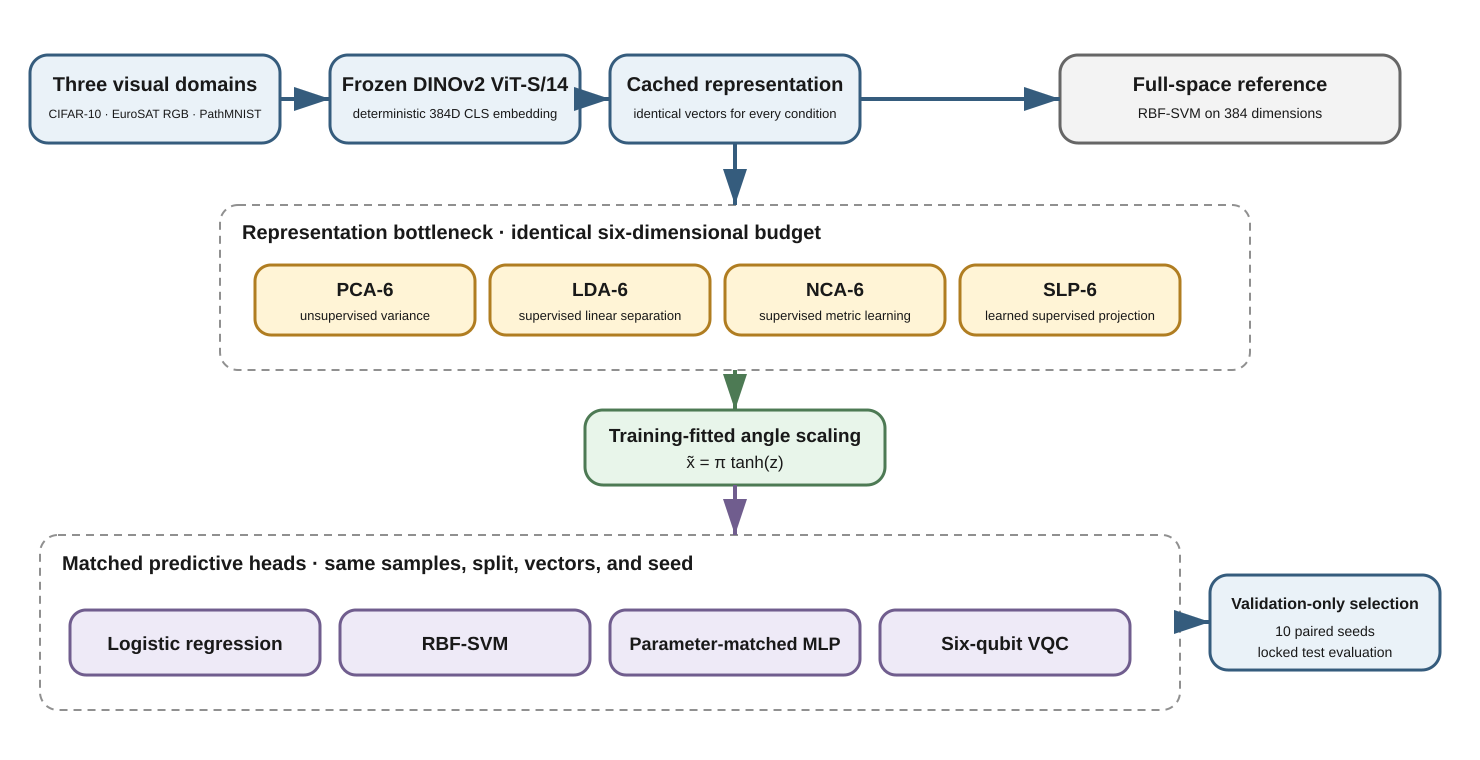

Editable draw.io source: results\figures\figure_01_pipeline.drawio


In [3]:
drawio_source = FIG / 'figure_01_pipeline.drawio'
pipeline_svg = FIG / 'figure_01_pipeline.svg'
assert drawio_source.exists() and pipeline_svg.exists()
display(SVG(filename=str(pipeline_svg)))
print(f'Editable draw.io source: {drawio_source.relative_to(ROOT)}')

## Dataset audit and sample montage

In [4]:
audit_rows = []
for dataset in ('cifar10','eurosat','pathmnist'):
    report = json.loads((ROOT/'data'/'audit'/f'{dataset}_audit_report.json').read_text(encoding='utf-8'))
    audit_rows.append({
        'Dataset': dataset,
        'Total decoded': report['total'],
        'Duplicate groups': report['duplicate_groups'],
        'Near-pair links': report['confirmed_near_pair_links'],
        'Quarantined': report['quarantined'],
        **{f'{k.title()} split': v for k,v in report['split_counts'].items()}
    })
audit_table = pd.DataFrame(audit_rows)
audit_table.to_csv(ROOT/'results'/'tables'/'dataset_audit_summary.csv', index=False)
audit_table

,Dataset,Total decoded,Duplicate groups,Near-pair links,Quarantined,Quarantine split,Test split,Train split,Val split
0,cifar10,60000,9,9,10,10.0,9995,44995,5000
1,eurosat,27000,5,7,0,NaN,4050,18900,4050
2,pathmnist,107180,3,15,9,9.0,7179,89991,10001


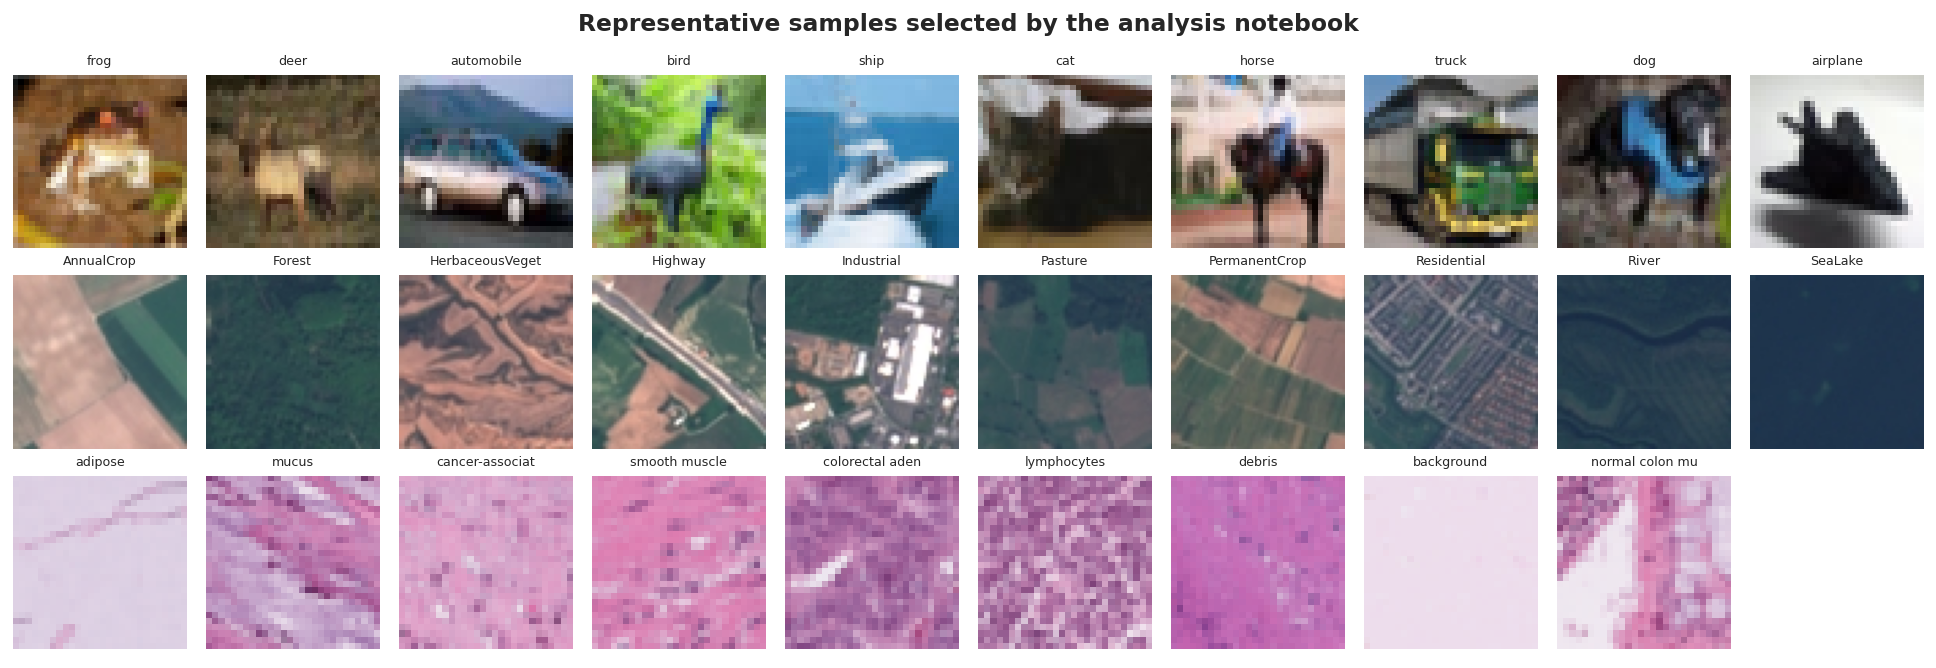

In [5]:
store = DatasetStore(download=False)
datasets = ('cifar10','eurosat','pathmnist')
fig, axes = plt.subplots(3, 10, figsize=(15, 5.2))
for row_idx, dataset in enumerate(datasets):
    manifest = pd.read_csv(ROOT/'data'/'manifests'/f'{dataset}.csv')
    usable = manifest[(manifest.split=='train') & (manifest.label>=0)]
    samples = usable.groupby('label', sort=True).head(1).head(10)
    for col_idx, (_, row) in enumerate(samples.iterrows()):
        axes[row_idx,col_idx].imshow(store.image(dataset,row.source_split,int(row.source_index)))
        axes[row_idx,col_idx].set_title(str(row.class_name)[:15], fontsize=7)
        axes[row_idx,col_idx].axis('off')
    for col_idx in range(len(samples),10): axes[row_idx,col_idx].axis('off')
    axes[row_idx,0].set_ylabel(dataset, fontsize=9, weight='bold')
fig.suptitle('Representative samples selected by the analysis notebook', fontsize=13, weight='bold')
fig.tight_layout()
save_figure(fig, 'figure_02_dataset_samples')
plt.show()

## Main performance results

In [6]:
test = pd.read_csv(ROOT/'results'/'metrics'/'all_test_metrics.csv')
validation = pd.read_csv(ROOT/'results'/'metrics'/'all_validation_metrics.csv')
summary = pd.read_csv(ROOT/'results'/'tables'/'main_performance_summary.csv')
display(summary.round(4))

,dataset,reducer,head,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,mcc_mean,...,nll_mean,nll_std,ece_mean,ece_std,brier_mean,brier_std,fit_seconds_mean,fit_seconds_std,inference_seconds_mean,inference_seconds_std
0,cifar10,full384,lr,0.9624,0.0015,0.9624,0.0014,0.9624,0.0014,0.9583,...,0.1209,0.0034,0.0152,0.0016,0.0567,0.0016,0.0344,0.0033,0.0149,0.0005
1,cifar10,full384,rbf,0.9647,0.0013,0.9646,0.0013,0.9647,0.0013,0.9607,...,0.1392,0.0042,0.0419,0.0038,0.0582,0.0016,1.1048,0.1113,1.5612,0.1656
2,cifar10,lda6,lr,0.8985,0.0155,0.8988,0.0155,0.8989,0.0155,0.8877,...,0.2896,0.0263,0.0270,0.0059,0.1463,0.0185,0.0200,0.0024,0.0015,0.0001
3,cifar10,lda6,mlp,0.8812,0.0153,0.8815,0.0153,0.8815,0.0153,0.8685,...,0.3730,0.0394,0.0384,0.0139,0.1775,0.0206,4.3426,1.8126,0.0133,0.0020
4,cifar10,lda6,rbf,0.9003,0.0154,0.9004,0.0153,0.9004,0.0153,0.8894,...,0.3001,0.0263,0.0264,0.0045,0.1460,0.0190,0.1181,0.0227,0.3816,0.0320
5,cifar10,lda6,vqc,0.6649,0.0320,0.6647,0.0329,0.6647,0.0329,0.6292,...,1.2148,0.0814,0.0403,0.0292,0.4714,0.0387,110.8367,36.9004,0.7451,0.0407
6,cifar10,nca6,lr,0.9326,0.0023,0.9325,0.0024,0.9326,0.0024,0.9251,...,0.2191,0.0088,0.0066,0.0014,0.1014,0.0038,0.0243,0.0032,0.0015,0.0002
7,cifar10,nca6,mlp,0.9191,0.0038,0.9196,0.0039,0.9196,0.0039,0.9108,...,0.2754,0.0140,0.0124,0.0045,0.1234,0.0061,5.0884,1.0913,0.0129,0.0017
8,cifar10,nca6,rbf,0.9381,0.0028,0.9381,0.0029,0.9381,0.0029,0.9312,...,0.2089,0.0071,0.0206,0.0025,0.0938,0.0035,0.0740,0.0146,0.2049,0.0073
9,cifar10,nca6,vqc,0.5296,0.0385,0.5366,0.0362,0.5366,0.0362,0.4862,...,1.5144,0.0917,0.0759,0.0310,0.6096,0.0342,89.4704,28.8185,0.7449,0.0302


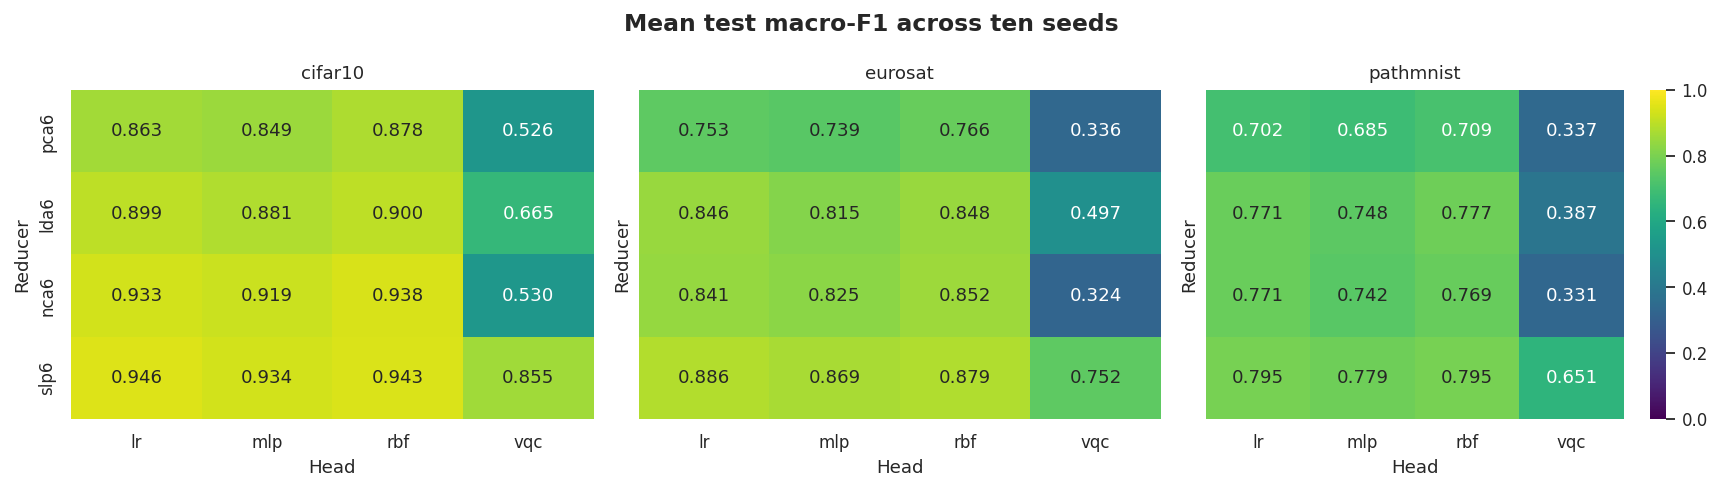

In [7]:
reduced = test[test.reducer!='full384']
means = reduced.groupby(['dataset','reducer','head']).macro_f1.mean().reset_index()
fig, axes = plt.subplots(1,3,figsize=(13.5,3.8),sharey=True)
for ax,(dataset,frame) in zip(axes,means.groupby('dataset')):
    pivot = frame.pivot(index='reducer',columns='head',values='macro_f1').reindex(['pca6','lda6','nca6','slp6'])
    sns.heatmap(pivot,annot=True,fmt='.3f',vmin=0,vmax=1,cmap='viridis',ax=ax,cbar=ax is axes[-1])
    ax.set_title(dataset); ax.set_xlabel('Head'); ax.set_ylabel('Reducer')
fig.suptitle('Mean test macro-F1 across ten seeds',fontsize=13,weight='bold')
fig.tight_layout()
save_figure(fig,'figure_03_macro_f1_heatmap')
plt.show()

## Compression penalty and quantum-head gap

In [8]:
compression = pd.read_csv(ROOT/'results'/'statistics'/'compression_penalty.csv')
head_gaps = pd.read_csv(ROOT/'results'/'statistics'/'head_gaps.csv')
display(compression.round(4))
display(head_gaps.round(4))

,dataset,reducer,rbf384_mean,rbf6_mean,compression_penalty_mean,ci_low,ci_high,n_seeds
0,cifar10,pca6,0.9647,0.8782,0.0865,0.0834,0.0899,10
1,cifar10,lda6,0.9647,0.9003,0.0644,0.0552,0.0740,10
2,cifar10,nca6,0.9647,0.9381,0.0266,0.0248,0.0282,10
3,cifar10,slp6,0.9647,0.9434,0.0213,0.0193,0.0232,10
4,eurosat,pca6,0.9314,0.7664,0.1650,0.1608,0.1690,10
5,eurosat,lda6,0.9314,0.8476,0.0837,0.0790,0.0893,10
6,eurosat,nca6,0.9314,0.8517,0.0797,0.0753,0.0840,10
7,eurosat,slp6,0.9314,0.8790,0.0523,0.0475,0.0578,10
8,pathmnist,pca6,0.8497,0.7092,0.1405,0.1311,0.1485,10
9,pathmnist,lda6,0.8497,0.7774,0.0723,0.0645,0.0806,10


,dataset,reducer,comparison,mean_difference,sd_difference,ci_low,ci_high,wilcoxon_p,n_seeds,holm_p
0,cifar10,pca6,vqc_minus_mlp,-0.3232,0.0415,-0.3489,-0.3001,0.002,10,0.0156
1,cifar10,pca6,vqc_minus_rbf,-0.3521,0.0416,-0.3773,-0.3285,0.002,10,0.0156
2,cifar10,lda6,vqc_minus_mlp,-0.2163,0.0329,-0.2360,-0.1972,0.002,10,0.0156
3,cifar10,lda6,vqc_minus_rbf,-0.2353,0.0350,-0.2558,-0.2146,0.002,10,0.0156
4,cifar10,nca6,vqc_minus_mlp,-0.3895,0.0383,-0.4114,-0.3668,0.002,10,0.0156
5,cifar10,nca6,vqc_minus_rbf,-0.4085,0.0387,-0.4309,-0.3858,0.002,10,0.0156
6,cifar10,slp6,vqc_minus_mlp,-0.0781,0.0152,-0.0876,-0.0699,0.002,10,0.0156
7,cifar10,slp6,vqc_minus_rbf,-0.0879,0.0144,-0.0966,-0.0799,0.002,10,0.0156
8,eurosat,pca6,vqc_minus_mlp,-0.4031,0.0313,-0.4212,-0.3846,0.002,10,0.0156
9,eurosat,pca6,vqc_minus_rbf,-0.4307,0.0348,-0.4511,-0.4098,0.002,10,0.0156


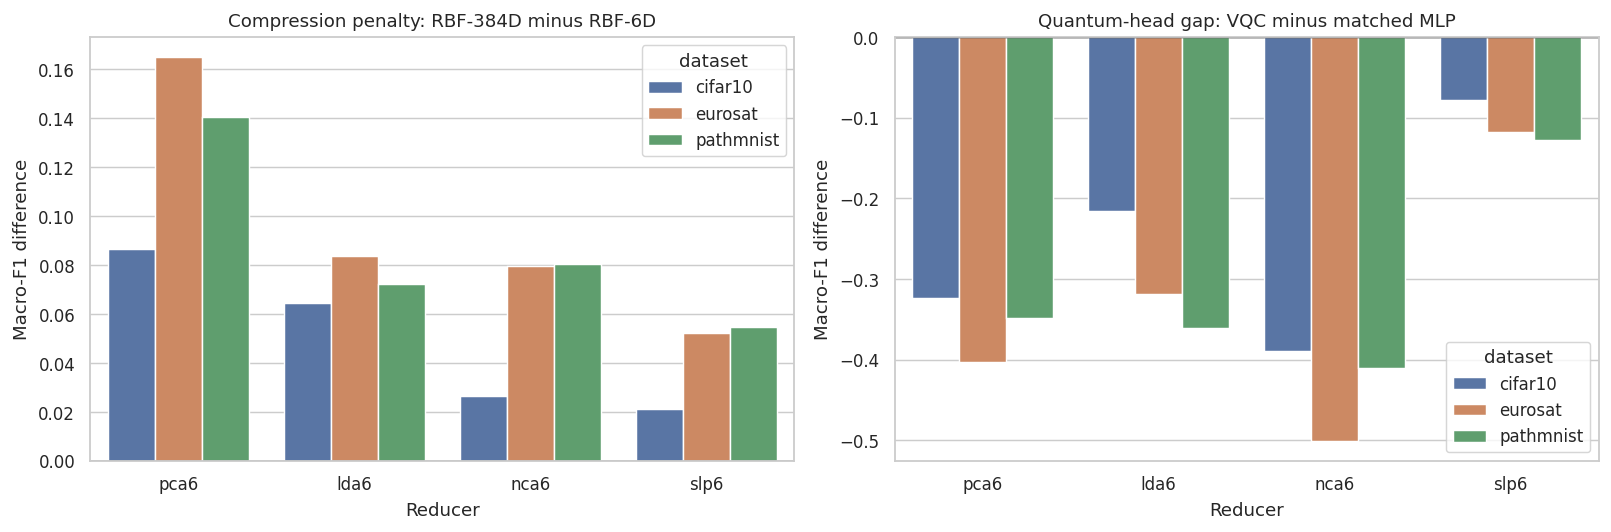

In [9]:
fig, axes = plt.subplots(1,2,figsize=(12.5,4.2))
sns.barplot(data=compression,x='reducer',y='compression_penalty_mean',hue='dataset',ax=axes[0])
axes[0].axhline(0,color='black',linewidth=.8); axes[0].set_title('Compression penalty: RBF-384D minus RBF-6D')
axes[0].set_ylabel('Macro-F1 difference'); axes[0].set_xlabel('Reducer')
mlp_gap = head_gaps[head_gaps.comparison=='vqc_minus_mlp']
sns.barplot(data=mlp_gap,x='reducer',y='mean_difference',hue='dataset',ax=axes[1])
axes[1].axhline(0,color='black',linewidth=.8); axes[1].set_title('Quantum-head gap: VQC minus matched MLP')
axes[1].set_ylabel('Macro-F1 difference'); axes[1].set_xlabel('Reducer')
fig.tight_layout(); save_figure(fig,'figure_04_compression_and_head_gaps'); plt.show()

## Representation geometry

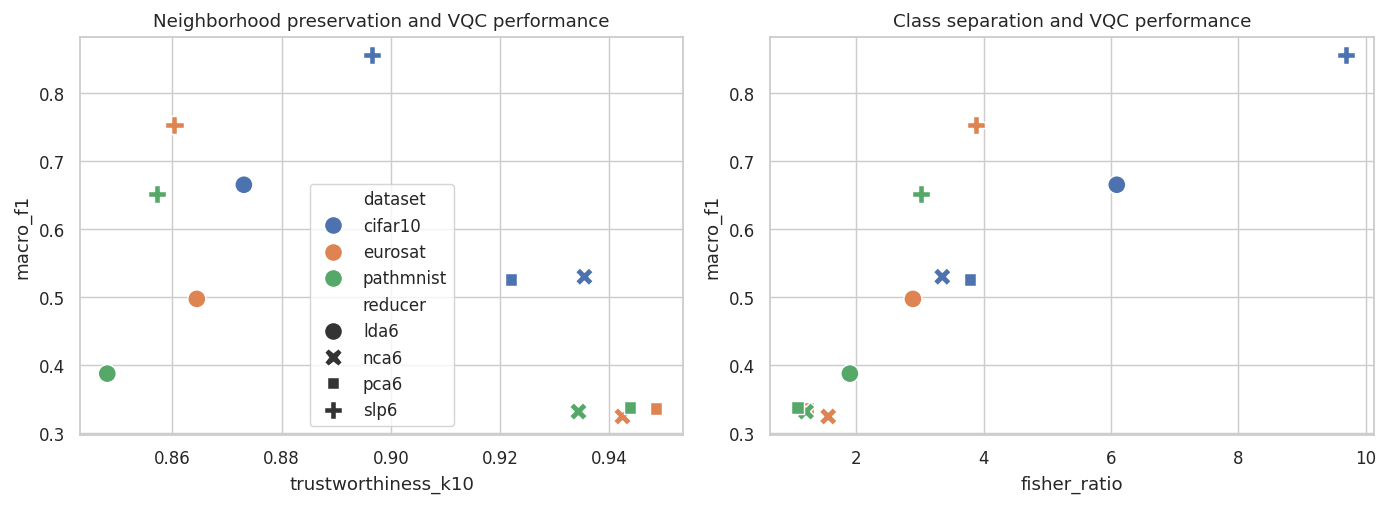

In [10]:
geometry = pd.read_csv(ROOT/'results'/'tables'/'representation_diagnostics.csv')
vqc_mean = test[(test['head']=='vqc') & (test['reducer']!='full384')].groupby(['dataset','reducer']).macro_f1.mean().reset_index()
geometry_mean = geometry.groupby(['dataset','reducer'],as_index=False).mean(numeric_only=True)
geometry_plot = geometry_mean.merge(vqc_mean,on=['dataset','reducer'])
fig, axes = plt.subplots(1,2,figsize=(10.8,4.0))
sns.scatterplot(data=geometry_plot,x='trustworthiness_k10',y='macro_f1',hue='dataset',style='reducer',s=100,ax=axes[0])
sns.scatterplot(data=geometry_plot,x='fisher_ratio',y='macro_f1',hue='dataset',style='reducer',s=100,ax=axes[1],legend=False)
axes[0].set_title('Neighborhood preservation and VQC performance')
axes[1].set_title('Class separation and VQC performance')
fig.tight_layout(); save_figure(fig,'figure_05_representation_geometry'); plt.show()

## Confusion matrices selected only by validation performance

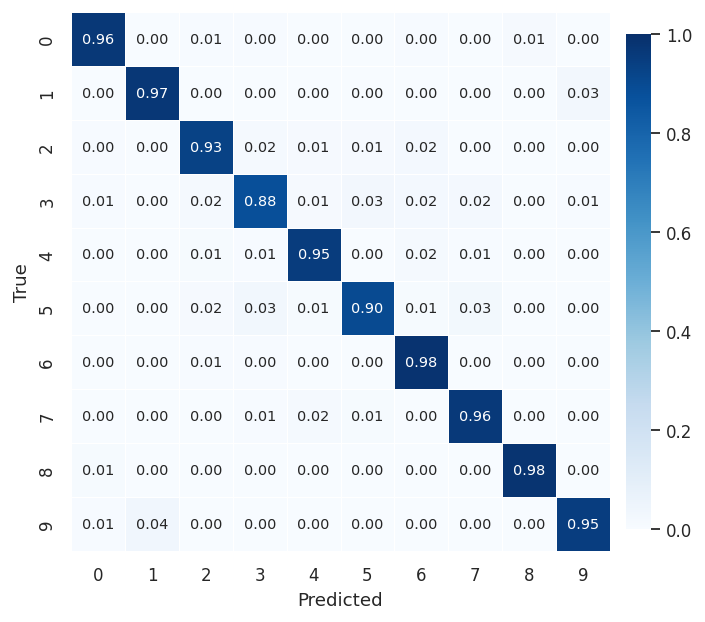

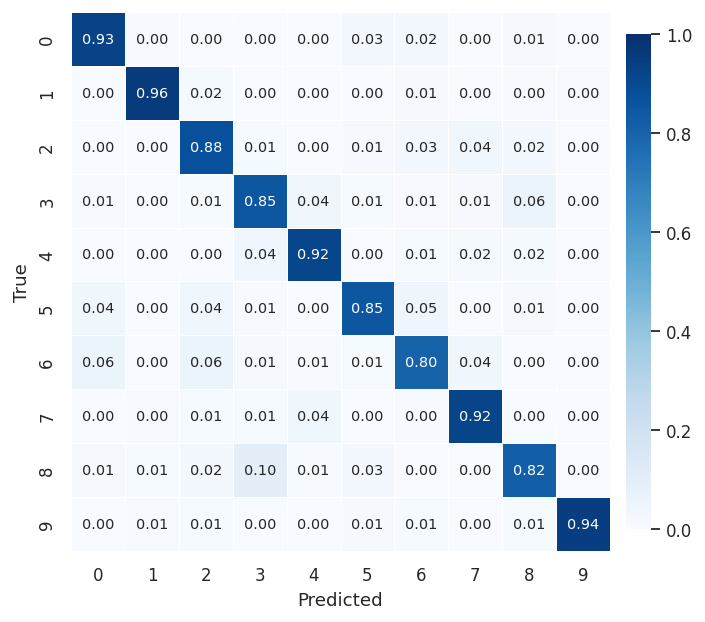

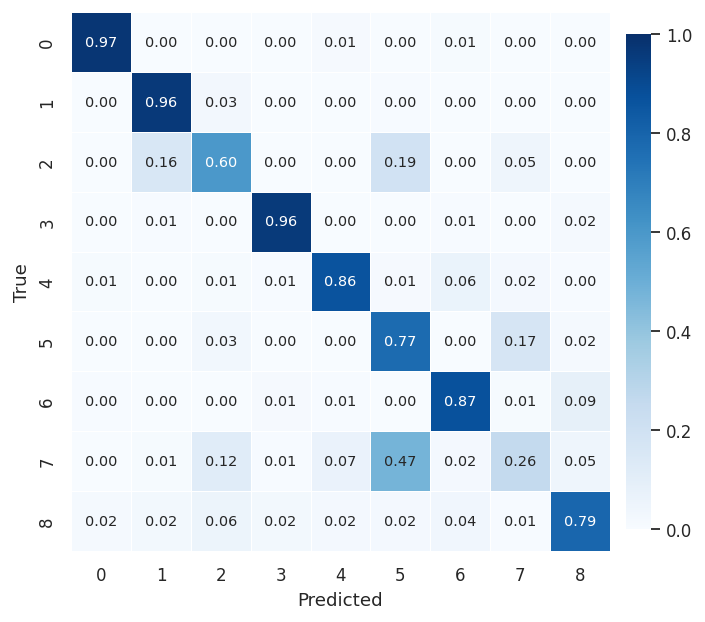

['A09-CIFAR10-SLP6-LR-S88',
 'A09-EUROSAT-SLP6-LR-S77',
 'A09-PATHMNIST-SLP6-RBF-S99']

In [11]:
ranked = (validation[validation.reducer!='full384']
          .groupby(['dataset','reducer','head'],as_index=False).macro_f1.mean()
          .sort_values(['dataset','macro_f1'],ascending=[True,False]).groupby('dataset').head(1))
selected_runs = []
figure_stems = {
    'cifar10': 'figure_06a_confusion_cifar10',
    'eurosat': 'figure_06b_confusion_eurosat',
    'pathmnist': 'figure_06c_confusion_pathmnist',
}
for _,choice in ranked.iterrows():
    candidates = validation[(validation['dataset']==choice['dataset'])&(validation['reducer']==choice['reducer'])&(validation['head']==choice['head'])].copy()
    representative_index = (candidates['macro_f1']-candidates['macro_f1'].mean()).abs().idxmin()
    seed_row = candidates.loc[representative_index]
    pred = pd.read_parquet(ROOT/'runs'/seed_row['run_id']/'predictions.parquet')
    matrix = confusion_matrix(pred.true_label,pred.predicted_label,normalize='true')
    # Display every normalized cell, including 0.00, so the published matrix is complete.
    annotations = np.vectorize(lambda value: f'{value:.2f}')(matrix)
    fig, ax = plt.subplots(figsize=(6.2,5.4))
    sns.heatmap(matrix,annot=annotations,fmt='',annot_kws={'fontsize':8.0},cmap='Blues',vmin=0,vmax=1,
                linewidths=.40,linecolor='white',square=True,ax=ax,cbar=True,
                cbar_kws={'shrink':0.82,'pad':0.025})
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    fig.subplots_adjust(top=0.98,bottom=0.12,left=0.12,right=0.93)
    save_figure(fig,figure_stems[choice['dataset']]); plt.show()
    selected_runs.append(seed_row['run_id'])
selected_runs

## Calibration

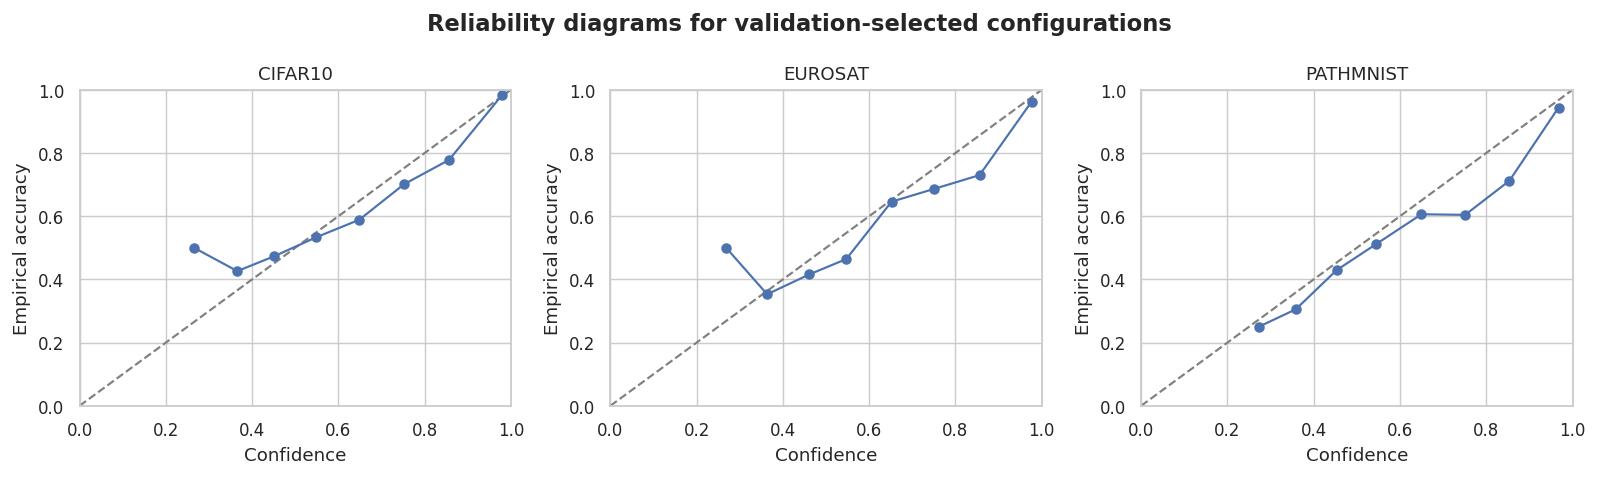

In [12]:
fig, axes = plt.subplots(1,3,figsize=(12.4,3.7))
for ax,run_id in zip(axes,selected_runs):
    pred = pd.read_parquet(ROOT/'runs'/run_id/'predictions.parquet')
    prob_cols = [c for c in pred if c.startswith('prob_class_')]
    probs = pred[prob_cols].to_numpy(); confidence=probs.max(1); correct=(probs.argmax(1)==pred.true_label.to_numpy()).astype(int)
    observed, predicted = calibration_curve(correct,confidence,n_bins=10,strategy='uniform')
    ax.plot([0,1],[0,1],'--',color='gray'); ax.plot(predicted,observed,'o-')
    ax.set_title(run_id.split('-')[1]); ax.set_xlabel('Confidence'); ax.set_ylabel('Empirical accuracy'); ax.set_xlim(0,1); ax.set_ylim(0,1)
fig.suptitle('Reliability diagrams for validation-selected configurations',fontsize=12.5,weight='bold')
fig.tight_layout(); save_figure(fig,'figure_07_calibration'); plt.show()

## Runtime and completion audit

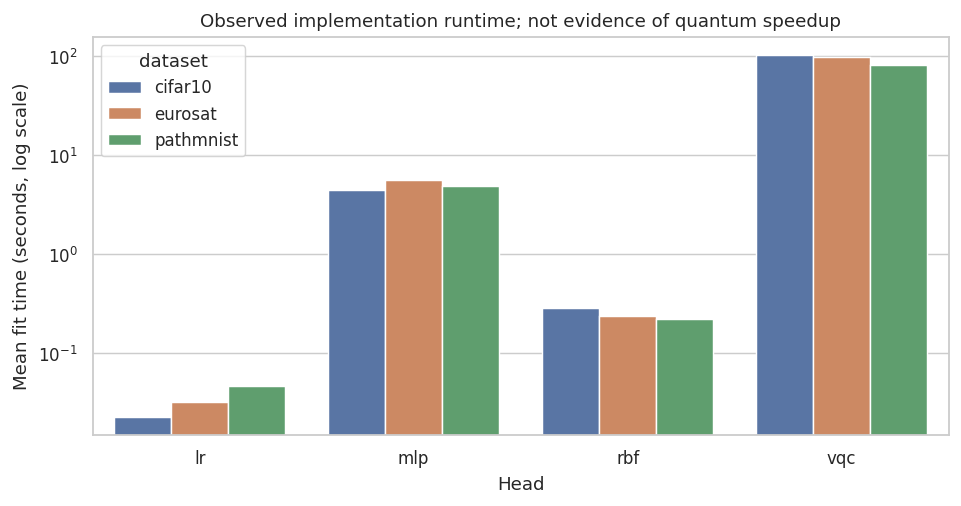

{'complete': 540,
 'expected_runs': 540,
 'failed_recorded': 0,
 'incomplete': 0,
 'runs': 'omitted from display'}

In [13]:
runtime = test.groupby(['dataset','head'],as_index=False).fit_seconds.mean()
fig, ax = plt.subplots(figsize=(7.5,4.0))
sns.barplot(data=runtime,x='head',y='fit_seconds',hue='dataset',ax=ax)
ax.set_yscale('log'); ax.set_ylabel('Mean fit time (seconds, log scale)'); ax.set_xlabel('Head')
ax.set_title('Observed implementation runtime; not evidence of quantum speedup')
fig.tight_layout(); save_figure(fig,'figure_08_runtime'); plt.show()

json.loads((ROOT/'results'/'completion_audit.json').read_text(encoding='utf-8')) | {'runs': 'omitted from display'}

## Interpretation boundary

The experiment supports claims about predictive behavior under a fixed six-dimensional information budget and analytic statevector simulation. It does not establish quantum advantage or quantum speedup. Cross-domain evidence is summarized through direction consistency and effect-size ranges; datasets are not treated as pooled independent replicates.